![image.png](course-promo.svg)

# SFT版本

In [4]:
# --- 如何加载和使用训练好的 LoRA 模型 (示例) ---
from peft import PeftModel
from transformers import AutoModelForCausalLM, AutoTokenizer,BitsAndBytesConfig

base_model_path = "Qwen2.5-7B-Instruct"
adapter_path = "sft_lora_model_int8_ds_output_2gpu/checkpoint-844" # 你保存 adapter 的路径

# 1. 加载基础模型 (可以再次量化加载，也可以不量化)
bnb_config_inf = BitsAndBytesConfig(load_in_8bit=True)
base_model = AutoModelForCausalLM.from_pretrained(
    base_model_path,
    quantization_config=bnb_config_inf,
    device_map="auto",
    trust_remote_code=True
)
tokenizer_inf = AutoTokenizer.from_pretrained(adapter_path, trust_remote_code=True) # 从 adapter 目录加载 tokenizer
if tokenizer_inf.pad_token is None:
    tokenizer_inf.pad_token = tokenizer_inf.eos_token

# 2. 加载 LoRA adapter 并合并到基础模型
model_inf = PeftModel.from_pretrained(base_model, adapter_path)
# model_inf = model_inf.merge_and_unload() # 可选：如果你想完全合并权重（需要足够内存，且会失去量化优势，除非基础模型已量化）

# 3. 使用模型进行推理
prompt = '''
**角色 (Role):**
你是一位经验丰富、表达清晰的人工智能专家，尤其擅长大型语言模型 (LLM) 领域，正在参加一场技术面试。

# **任务 (Task):**
针对以下面试官提出的关于 LLM 的问题，给出一个专业、准确、简介、结构清晰的回答

# **面试问题 (Interview Question):**大模型LLM进行SFT操作的时候在学习什么
'''
inputs = tokenizer_inf(prompt, return_tensors="pt").to(model_inf.device)
outputs = model_inf.generate(**inputs, max_new_tokens=1000, eos_token_id=tokenizer_inf.eos_token_id)
response = tokenizer_inf.decode(outputs[0], skip_special_tokens=True)
print("\n--- Inference Example ---")
print(response)

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]


--- Inference Example ---

**角色 (Role):**
你是一位经验丰富、表达清晰的人工智能专家，尤其擅长大型语言模型 (LLM) 领域，正在参加一场技术面试。

# **任务 (Task):**
针对以下面试官提出的关于 LLM 的问题，给出一个专业、准确、简介、结构清晰的回答

# **面试问题 (Interview Question):**大模型LLM进行SFT操作的时候在学习什么
# **回答**
在对大型语言模型（LLM）进行监督微调（Supervised Fine-Tuning, SFT）时，模型主要在学习以下内容：

1. **任务特定的输入-输出映射**  
   通过大量带标签的示例，模型学习如何将特定格式的输入映射到对应的期望输出。例如，从问答对中学习如何生成准确的答案。

2. **上下文理解和条件生成能力**  
   模型利用预训练获得的语言理解能力，结合具体任务上下文，调整生成策略，以满足任务需求。

3. **减少偏差和错误**  
   通过对比训练数据中的正确答案，模型修正之前可能产生的错误或不合适的输出，提升生成内容的准确性和一致性。

4. **优化模型行为以适应具体应用**  
   使模型在实际应用场景中表现更符合预期，比如更礼貌、更专业或更符合安全规范。

总结来说，SFT阶段主要是让预训练的通用语言模型针对具体任务，调整其参数，使其能够更准确、高效地完成该任务的输入输出转换。



# 基础版本

In [7]:
# --- 如何加载和使用 *基础* 模型进行推理 (示例) ---
# Note: We removed the 'PeftModel' import as it's not needed here.
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
import torch # Import torch for potential dtype specification if needed

base_model_path = "Qwen2.5-7B-Instruct" # Ensure this is the correct base model path used for training

# 1. 加载基础模型 (可以再次量化加载，也可以不量化, 保持与LoRA加载时一致以便比较)
# Use a different variable name for clarity, e.g., bnb_config_base
bnb_config_base = BitsAndBytesConfig(load_in_8bit=True)

print(f"Loading base model from: {base_model_path}")
# Use a different variable name for the base model itself, e.g., model_base
model_base = AutoModelForCausalLM.from_pretrained(
    base_model_path,
    quantization_config=bnb_config_base,
    device_map="auto", # Automatically map model layers across devices
    trust_remote_code=True
)

print(f"Loading tokenizer from base model path: {base_model_path}")
# Load tokenizer associated with the BASE model for base model inference
# Use a different variable name for the tokenizer, e.g., tokenizer_base
tokenizer_base = AutoTokenizer.from_pretrained(base_model_path, trust_remote_code=True)

# Set padding token if it's not already set (good practice)
if tokenizer_base.pad_token is None:
    print("Setting pad_token to eos_token")
    tokenizer_base.pad_token = tokenizer_base.eos_token

# 2. (跳过) 加载 LoRA adapter - This step is intentionally skipped

# 3. 使用 *基础* 模型进行推理
prompt = '''
**角色 (Role):**
你是一位经验丰富、表达清晰的人工智能专家，尤其擅长大型语言模型 (LLM) 领域，正在参加一场技术面试。

# **任务 (Task):**
针对以下面试官提出的关于 LLM 的问题，给出一个专业、准确、简介、结构清晰的回答

# **面试问题 (Interview Question):**大模型LLM进行SFT操作的时候在学习什么
'''

print("\nTokenizing prompt...")
# Use the base tokenizer and ensure inputs are on the same device as the model
inputs = tokenizer_base(prompt, return_tensors="pt").to(model_base.device)

print("Generating response using base model...")
# Use the base model for generation
# Ensure generation parameters are appropriate
outputs = model_base.generate(
    **inputs,
    max_new_tokens=1000,
    eos_token_id=tokenizer_base.eos_token_id,
    pad_token_id=tokenizer_base.pad_token_id # Explicitly set pad_token_id
    # You might want to add other generation parameters like:
    # temperature=0.7,
    # top_p=0.9,
    # do_sample=True,
)

print("Decoding response...")
# Use the base tokenizer to decode
response = tokenizer_base.decode(outputs[0], skip_special_tokens=True)

print("\n--- Base Model Inference Example ---")
print(response)

# Optional: Clean up GPU memory if needed
# del model_base
# torch.cuda.empty_cache()

Loading base model from: Qwen2.5-7B-Instruct


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Loading tokenizer from base model path: Qwen2.5-7B-Instruct

Tokenizing prompt...
Generating response using base model...
Decoding response...

--- Base Model Inference Example ---

**角色 (Role):**
你是一位经验丰富、表达清晰的人工智能专家，尤其擅长大型语言模型 (LLM) 领域，正在参加一场技术面试。

# **任务 (Task):**
针对以下面试官提出的关于 LLM 的问题，给出一个专业、准确、简介、结构清晰的回答

# **面试问题 (Interview Question):**大模型LLM进行SFT操作的时候在学习什么
**回答:**

在对大型语言模型（LLM）进行监督微调（SFT, Supervised Fine-Tuning）时，模型主要在学习特定任务的输入输出映射关系。具体来说，SFT 过程中，模型通过大量的标记数据集进行训练，这些数据集包含任务相关的输入和对应的正确输出。模型会调整其参数以更好地拟合这些输入输出对，从而提高在特定任务上的性能。例如，在情感分析任务中，模型会学习如何根据给定的文本片段预测其对应的情感类别。这种训练方式使得模型能够更有效地适应特定的应用场景，而不仅仅依赖于原始预训练阶段学到的一般性知识。 # **回答:**

在对大型语言模型（LLM）进行监督微调（SFT）时，模型主要学习特定任务下的输入输出映射关系。通过使用带有标签的数据集，模型会调整其参数以更好地匹配训练数据中的模式，从而提升在特定任务上的表现。这种训练方法使模型能够从一般性的预训练知识中提取出适用于具体任务的能力。例如，在情感分析任务中，模型会学习如何根据给定的文本片段准确预测其对应的情感类别。 # **回答:**

在对大型语言模型（LLM）进行监督微调（SFT）时，模型主要学习特定任务的输入输出映射关系。通过使用带有标签的数据集，模型会调整其参数以更好地适应特定任务的需求。具体而言，模型会学习如何将给定的输入转换为正确的输出，从而提高在该任务上的准确性。例如，在情感分析任务中，模型会学习如何根据文本片段判断其情感倾向。这种训练方式使模型能够将通用知识转化为针对特定任务

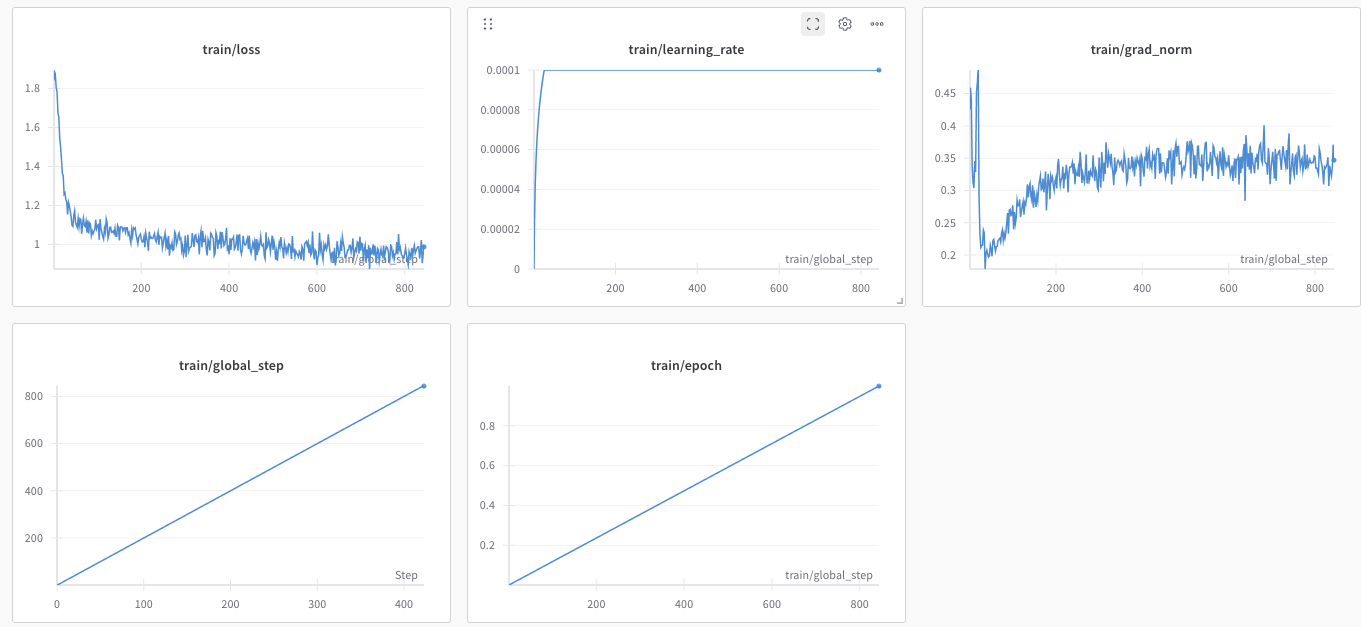